# Task 2: Exploratory Data Analysis - Sports (Indian Premier League)
**Internship:** Intern Infobyte | **Domain:** Machine Learning / Data Science | **Tool:** Python (Pandas, Matplotlib, Seaborn) in Jupyter Notebook

### Objectives (from the task sheet)
1. **EDA:** Analyze the IPL dataset (matches + deliveries).
2. **Success Analysis:** Identify the most successful teams, top-performing players, and the factors that contribute to wins or losses.
3. **Endorsement Recommendations:** Suggest teams or players for product endorsements based on performance and popularity.
4. **Tool of choice:** Python.
5. **Advanced Storytelling:** Storyboard with annotations, images and audio explanation (see the last section).

### Dataset
- `matches.csv` - one row per match (season, teams, toss, winner, player of the match, venue...)
- `deliveries.csv` - one row per ball (batsman, bowler, runs, wickets...)

## Step 1: Import libraries

In [3]:
import os, warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (11, 5)
plt.rcParams['axes.titlesize'] = 14
os.makedirs('images', exist_ok=True)   # charts are saved here for the storyboard

def save(name):
    plt.tight_layout()
    plt.savefig(f'images/{name}.png', dpi=150, bbox_inches='tight')
    plt.show()

## Step 2: Load the data

In [38]:
matches = pd.read_csv('matches.csv')
deliveries = pd.read_csv('deliveries.csv')
print('matches   :', matches.shape)
print('deliveries:', deliveries.shape)
matches.head()

matches   : (756, 18)
deliveries: (179078, 21)


,id,season,city,date,team1,team2,toss_winner,toss_decision,result,dl_applied,winner,win_by_runs,win_by_wickets,player_of_match,venue,umpire1,umpire2,umpire3
0,1,2017,Hyderabad,2017-04-05,Sunrisers Hyderabad,Royal Challengers Bangalore,Royal Challengers Bangalore,field,normal,0,Sunrisers Hyderabad,35,0,Yuvraj Singh,"Rajiv Gandhi International Stadium, Uppal",AY Dandekar,NJ Llong,NaN
1,2,2017,Pune,2017-04-06,Mumbai Indians,Rising Pune Supergiant,Rising Pune Supergiant,field,normal,0,Rising Pune Supergiant,0,7,SPD Smith,Maharashtra Cricket Association Stadium,A Nand Kishore,S Ravi,NaN
2,3,2017,Rajkot,2017-04-07,Gujarat Lions,Kolkata Knight Riders,Kolkata Knight Riders,field,normal,0,Kolkata Knight Riders,0,10,CA Lynn,Saurashtra Cricket Association Stadium,Nitin Menon,CK Nandan,NaN
3,4,2017,Indore,2017-04-08,Rising Pune Supergiant,Kings XI Punjab,Kings XI Punjab,field,normal,0,Kings XI Punjab,0,6,GJ Maxwell,Holkar Cricket Stadium,AK Chaudhary,C Shamshuddin,NaN
4,5,2017,Bangalore,2017-04-08,Royal Challengers Bangalore,Delhi Daredevils,Royal Challengers Bangalore,bat,normal,0,Royal Challengers Bangalore,15,0,KM Jadhav,M Chinnaswamy Stadium,NaN,NaN,NaN


In [5]:
deliveries.head()

,match_id,inning,batting_team,bowling_team,over,ball,batsman,non_striker,bowler,is_super_over,...,bye_runs,legbye_runs,noball_runs,penalty_runs,batsman_runs,extra_runs,total_runs,player_dismissed,dismissal_kind,fielder
0,1,1,Sunrisers Hyderabad,Royal Challengers Bangalore,1,1,DA Warner,S Dhawan,TS Mills,0,...,0,0,0,0,0,0,0,NaN,NaN,NaN
1,1,1,Sunrisers Hyderabad,Royal Challengers Bangalore,1,2,DA Warner,S Dhawan,TS Mills,0,...,0,0,0,0,0,0,0,NaN,NaN,NaN
2,1,1,Sunrisers Hyderabad,Royal Challengers Bangalore,1,3,DA Warner,S Dhawan,TS Mills,0,...,0,0,0,0,4,0,4,NaN,NaN,NaN
3,1,1,Sunrisers Hyderabad,Royal Challengers Bangalore,1,4,DA Warner,S Dhawan,TS Mills,0,...,0,0,0,0,0,0,0,NaN,NaN,NaN
4,1,1,Sunrisers Hyderabad,Royal Challengers Bangalore,1,5,DA Warner,S Dhawan,TS Mills,0,...,0,0,0,0,0,2,2,NaN,NaN,NaN


## Step 3: Understand and clean the data
Checks: data types, missing values, duplicates, and inconsistent team names.

In [6]:
matches.info()
print()
print(matches.isnull().sum())
print('Duplicate matches:', matches.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 756 entries, 0 to 755
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   id               756 non-null    int64
 1   season           756 non-null    int64
 2   city             749 non-null    str  
 3   date             756 non-null    str  
 4   team1            756 non-null    str  
 5   team2            756 non-null    str  
 6   toss_winner      756 non-null    str  
 7   toss_decision    756 non-null    str  
 8   result           756 non-null    str  
 9   dl_applied       756 non-null    int64
 10  winner           752 non-null    str  
 11  win_by_runs      756 non-null    int64
 12  win_by_wickets   756 non-null    int64
 13  player_of_match  752 non-null    str  
 14  venue            756 non-null    str  
 15  umpire1          754 non-null    str  
 16  umpire2          754 non-null    str  
 17  umpire3          119 non-null    str  
dtypes: int64(5), str(13)


In [7]:
print(matches[matches['winner'].isnull()][['id','season','team1','team2','result']])
print()
print(matches[matches['city'].isnull()][['id','season','venue']])

        id  season                        team1                        team2  \
300    301    2011             Delhi Daredevils                Pune Warriors   
545    546    2015  Royal Challengers Bangalore             Rajasthan Royals   
570    571    2015             Delhi Daredevils  Royal Challengers Bangalore   
744  11340    2019  Royal Challengers Bangalore             Rajasthan Royals   

        result  
300  no result  
545  no result  
570  no result  
744  no result  

      id  season                                venue
461  462    2014  Dubai International Cricket Stadium
462  463    2014  Dubai International Cricket Stadium
466  467    2014  Dubai International Cricket Stadium
468  469    2014  Dubai International Cricket Stadium
469  470    2014  Dubai International Cricket Stadium
474  475    2014  Dubai International Cricket Stadium
476  477    2014  Dubai International Cricket Stadium


**Cleaning decisions**
- `Rising Pune Supergiants` and `Rising Pune Supergiant` are the same team -> merge.
- `Delhi Daredevils` was renamed `Delhi Capitals` (same franchise) -> merge.
- Matches with no winner are abandoned / no-result matches -> mark as `No Result`, exclude from win percentages.
- 7 missing cities are all matches at the Dubai International Cricket Stadium (2014) -> fill with Dubai.
- `date` has two different formats (e.g. `2017-04-05` and `07/04/18`) -> parse each format separately (a single parser would swap day and month).
- `umpire3` is almost entirely empty and not useful -> drop.

In [8]:
team_fix = {'Rising Pune Supergiants': 'Rising Pune Supergiant',
            'Delhi Daredevils': 'Delhi Capitals'}

for col in ['team1', 'team2', 'toss_winner', 'winner']:
    matches[col] = matches[col].replace(team_fix)
for col in ['batting_team', 'bowling_team']:
    deliveries[col] = deliveries[col].replace(team_fix)

matches['winner'] = matches['winner'].fillna('No Result')
matches['player_of_match'] = matches['player_of_match'].fillna('No Award')
matches.loc[matches['city'].isnull(), 'city'] = 'Dubai'
# dates come in 2 formats: 2008-2017 are 'YYYY-MM-DD', 2018-2019 are 'DD/MM/YY' -> parse each format separately
iso = matches['date'].str.contains('-')
matches['date'] = pd.concat([pd.to_datetime(matches.loc[iso, 'date'], format='%Y-%m-%d'),
                             pd.to_datetime(matches.loc[~iso, 'date'], format='%d/%m/%y')]).sort_index()
matches = matches.drop(columns=['umpire3'])

# add season to deliveries
deliveries = deliveries.merge(matches[['id', 'season']], left_on='match_id', right_on='id', how='left').drop(columns='id')

print('Teams:', sorted(matches['team1'].unique()))
print('Seasons:', matches['season'].min(), 'to', matches['season'].max())

Teams: ['Chennai Super Kings', 'Deccan Chargers', 'Delhi Capitals', 'Gujarat Lions', 'Kings XI Punjab', 'Kochi Tuskers Kerala', 'Kolkata Knight Riders', 'Mumbai Indians', 'Pune Warriors', 'Rajasthan Royals', 'Rising Pune Supergiant', 'Royal Challengers Bangalore', 'Sunrisers Hyderabad']
Seasons: 2008 to 2019


In [9]:
# matches that have a result
played = matches[matches['winner'] != 'No Result'].copy()
print('Total matches:', len(matches), '| With a result:', len(played), '| No result:', len(matches) - len(played))
matches.describe(include='all').T.head(12)

Total matches: 756 | With a result: 752 | No result: 4


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
id,756.0,NaN,NaN,NaN,1792.178571,1.0,189.75,378.5,567.25,11415.0,3464.478148
season,756.0,NaN,NaN,NaN,2013.444444,2008.0,2011.0,2013.0,2016.0,2019.0,3.366895
city,756,33,Mumbai,101,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date,756,NaN,NaN,NaN,2013-10-07 06:22:51.428571,2008-04-18 00:00:00,2011-04-16 00:00:00,2013-05-09 12:00:00,2016-05-18 06:00:00,2019-05-12 00:00:00,NaN
team1,756,13,Mumbai Indians,101,NaN,NaN,NaN,NaN,NaN,NaN,NaN
team2,756,13,Delhi Capitals,99,NaN,NaN,NaN,NaN,NaN,NaN,NaN
toss_winner,756,13,Mumbai Indians,98,NaN,NaN,NaN,NaN,NaN,NaN,NaN
toss_decision,756,2,field,463,NaN,NaN,NaN,NaN,NaN,NaN,NaN
result,756,3,normal,743,NaN,NaN,NaN,NaN,NaN,NaN,NaN
dl_applied,756.0,NaN,NaN,NaN,0.025132,0.0,0.0,0.0,0.0,1.0,0.15663


## Step 4: Exploratory Data Analysis (EDA)
### 4.1 Matches per season

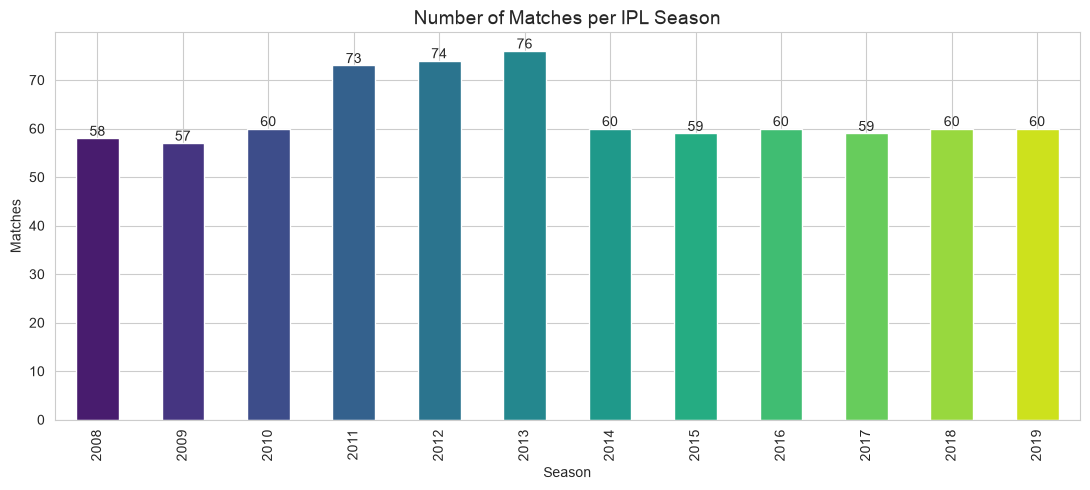

In [10]:
season_counts = matches['season'].value_counts().sort_index()
ax = season_counts.plot(kind='bar', color=sns.color_palette('viridis', len(season_counts)))
for i, v in enumerate(season_counts.values):
    ax.text(i, v + 0.5, v, ha='center')
plt.title('Number of Matches per IPL Season'); plt.xlabel('Season'); plt.ylabel('Matches')
save('01_matches_per_season')

Seasons 2011 to 2013 have the most matches (73 to 76) because the league had 10 teams and a longer format. All other seasons have about 57 to 60 matches.

### 4.2 Toss analysis

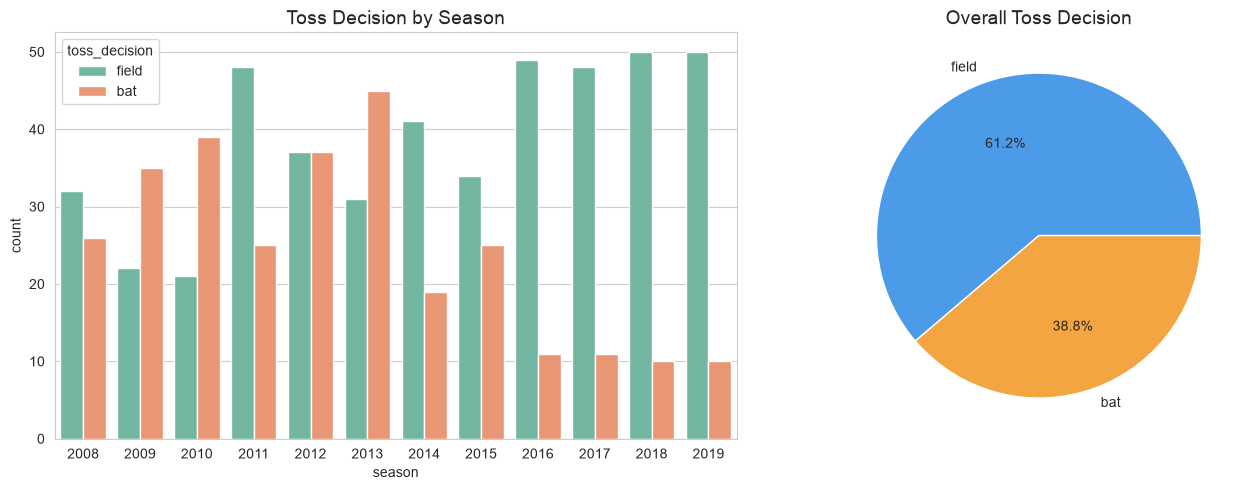

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.countplot(x='season', hue='toss_decision', data=matches, ax=axes[0], palette='Set2')
axes[0].set_title('Toss Decision by Season')
matches['toss_decision'].value_counts().plot(kind='pie', autopct='%1.1f%%', ax=axes[1], colors=['#4c9be8', '#f2a541'])
axes[1].set_title('Overall Toss Decision'); axes[1].set_ylabel('')
save('02_toss_decision')

In [12]:
played['toss_win_match_win'] = played['toss_winner'] == played['winner']
toss_impact = played['toss_win_match_win'].mean() * 100
print(f'Toss winner also won the match: {toss_impact:.1f}%')

# by decision
print(played.groupby('toss_decision')['toss_win_match_win'].mean().mul(100).round(1))

Toss winner also won the match: 52.3%
toss_decision
bat      45.9
field    56.3
Name: toss_win_match_win, dtype: float64


The toss gives only a small advantage, so it is **not** a strong factor in who wins.

### 4.3 Bat first vs chase

Teams batting first won: 44.8% | Chasing teams won: 55.2%


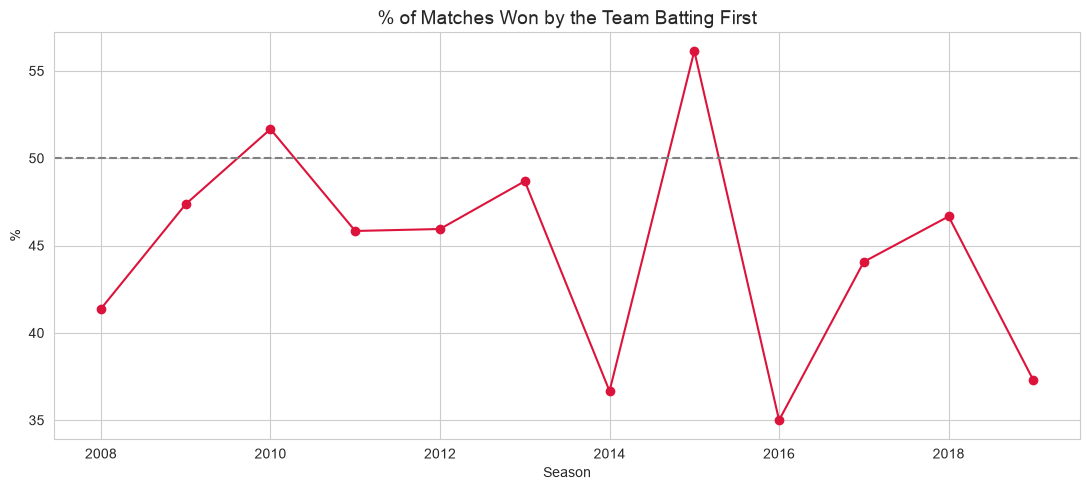

In [13]:
played['bat_first_won'] = played['win_by_runs'] > 0
bat_first = played['bat_first_won'].mean() * 100
print(f'Teams batting first won: {bat_first:.1f}% | Chasing teams won: {100-bat_first:.1f}%')

trend = played.groupby('season')['bat_first_won'].mean().mul(100)
trend.plot(marker='o', color='crimson')
plt.axhline(50, color='grey', linestyle='--')
plt.title('% of Matches Won by the Team Batting First'); plt.ylabel('%'); plt.xlabel('Season')
save('03_bat_first_vs_chase')

### 4.4 Venues

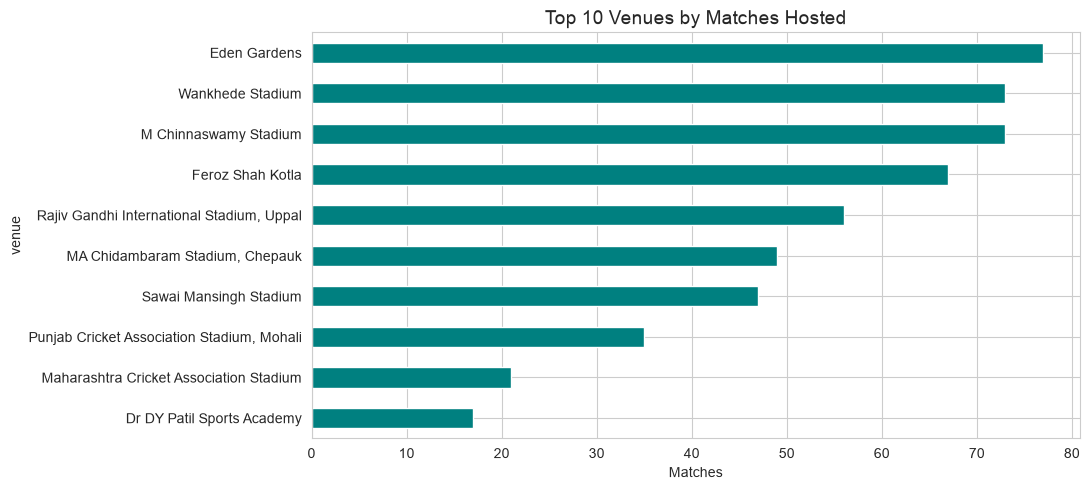

In [14]:
top_venues = matches['venue'].value_counts().head(10)
top_venues.sort_values().plot(kind='barh', color='teal')
plt.title('Top 10 Venues by Matches Hosted'); plt.xlabel('Matches')
save('04_top_venues')

In [15]:
# Which venues favour batting first?
v = played.groupby('venue').agg(matches=('id', 'count'), bat_first_win_pct=('bat_first_won', lambda x: x.mean() * 100))
v[v['matches'] >= 20].sort_values('bat_first_win_pct', ascending=False).round(1)

,matches,bat_first_win_pct
venue,,
"MA Chidambaram Stadium, Chepauk",49,61.2
Feroz Shah Kotla,66,50.0
Wankhede Stadium,73,47.9
"Punjab Cricket Association Stadium, Mohali",35,42.9
M Chinnaswamy Stadium,71,42.3
Eden Gardens,77,41.6
"Rajiv Gandhi International Stadium, Uppal",56,41.1
Maharashtra Cricket Association Stadium,21,33.3
Sawai Mansingh Stadium,47,31.9


### 4.5 Biggest wins and Super-over / DL matches

In [16]:
print('Biggest wins by runs:')
print(played.nlargest(5, 'win_by_runs')[['season', 'team1', 'team2', 'winner', 'win_by_runs']].to_string(index=False))
print('\nBiggest wins by wickets (10 wickets):', (played['win_by_wickets'] == 10).sum(), 'matches')
print('Matches decided by D/L method:', matches['dl_applied'].sum())
print('Tied matches (result = tie):', (matches['result'] == 'tie').sum())

Biggest wins by runs:
 season                       team1                       team2                      winner  win_by_runs
   2017              Mumbai Indians              Delhi Capitals              Mumbai Indians          146
   2016 Royal Challengers Bangalore               Gujarat Lions Royal Challengers Bangalore          144
   2008       Kolkata Knight Riders Royal Challengers Bangalore       Kolkata Knight Riders          140
   2015 Royal Challengers Bangalore             Kings XI Punjab Royal Challengers Bangalore          138
   2013 Royal Challengers Bangalore               Pune Warriors Royal Challengers Bangalore          130

Biggest wins by wickets (10 wickets): 11 matches
Matches decided by D/L method: 19
Tied matches (result = tie): 9


### 4.6 Scoring trend across seasons

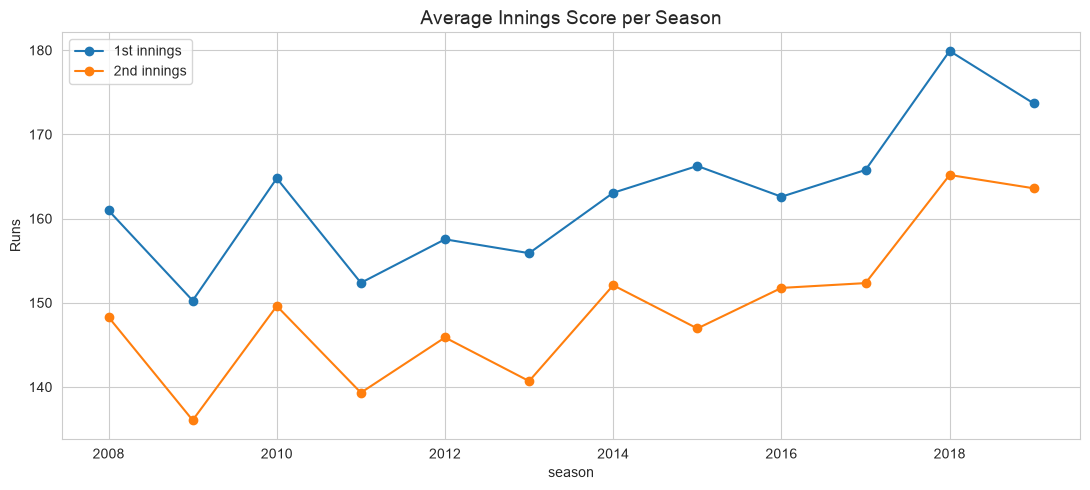

,1st innings,2nd innings
season,,
2008,161.0,148.3
2009,150.3,136.1
2010,164.8,149.6
2011,152.4,139.3
2012,157.5,145.9
2013,155.9,140.7
2014,163.1,152.1
2015,166.3,146.9
2016,162.6,151.8


In [17]:
reg = deliveries[deliveries['is_super_over'] == 0]
inn = reg.groupby(['season', 'match_id', 'inning'])['total_runs'].sum().reset_index()
avg_score = inn[inn['inning'].isin([1, 2])].groupby(['season', 'inning'])['total_runs'].mean().unstack()
avg_score.columns = ['1st innings', '2nd innings']
avg_score.plot(marker='o')
plt.title('Average Innings Score per Season'); plt.ylabel('Runs')
save('05_avg_score_trend')
avg_score.round(1)

## Step 5: Success Analysis - Teams
### 5.1 Most successful teams (wins, win %, titles)

In [18]:
team_matches = pd.concat([played['team1'], played['team2']]).value_counts()
team_wins = played['winner'].value_counts()
team_stats = pd.DataFrame({'matches': team_matches, 'wins': team_wins}).fillna(0)
team_stats['win_pct'] = (team_stats['wins'] / team_stats['matches'] * 100).round(1)

# the final = last match of each season
finals = matches.sort_values(['season', 'date', 'id']).groupby('season').tail(1)
titles = finals['winner'].value_counts()
team_stats['titles'] = titles
team_stats['titles'] = team_stats['titles'].fillna(0).astype(int)
team_stats = team_stats.sort_values('wins', ascending=False)
print(finals[['season', 'winner']].to_string(index=False))
team_stats

 season                winner
   2008      Rajasthan Royals
   2009       Deccan Chargers
   2010   Chennai Super Kings
   2011   Chennai Super Kings
   2012 Kolkata Knight Riders
   2013        Mumbai Indians
   2014 Kolkata Knight Riders
   2015        Mumbai Indians
   2016   Sunrisers Hyderabad
   2017        Mumbai Indians
   2018   Chennai Super Kings
   2019        Mumbai Indians


,matches,wins,win_pct,titles
Mumbai Indians,187,109,58.3,4
Chennai Super Kings,164,100,61.0,3
Kolkata Knight Riders,178,92,51.7,2
Royal Challengers Bangalore,177,84,47.5,0
Kings XI Punjab,176,82,46.6,0
Delhi Capitals,175,77,44.0,0
Rajasthan Royals,145,75,51.7,1
Sunrisers Hyderabad,108,58,53.7,1
Deccan Chargers,75,29,38.7,1
Rising Pune Supergiant,30,15,50.0,0


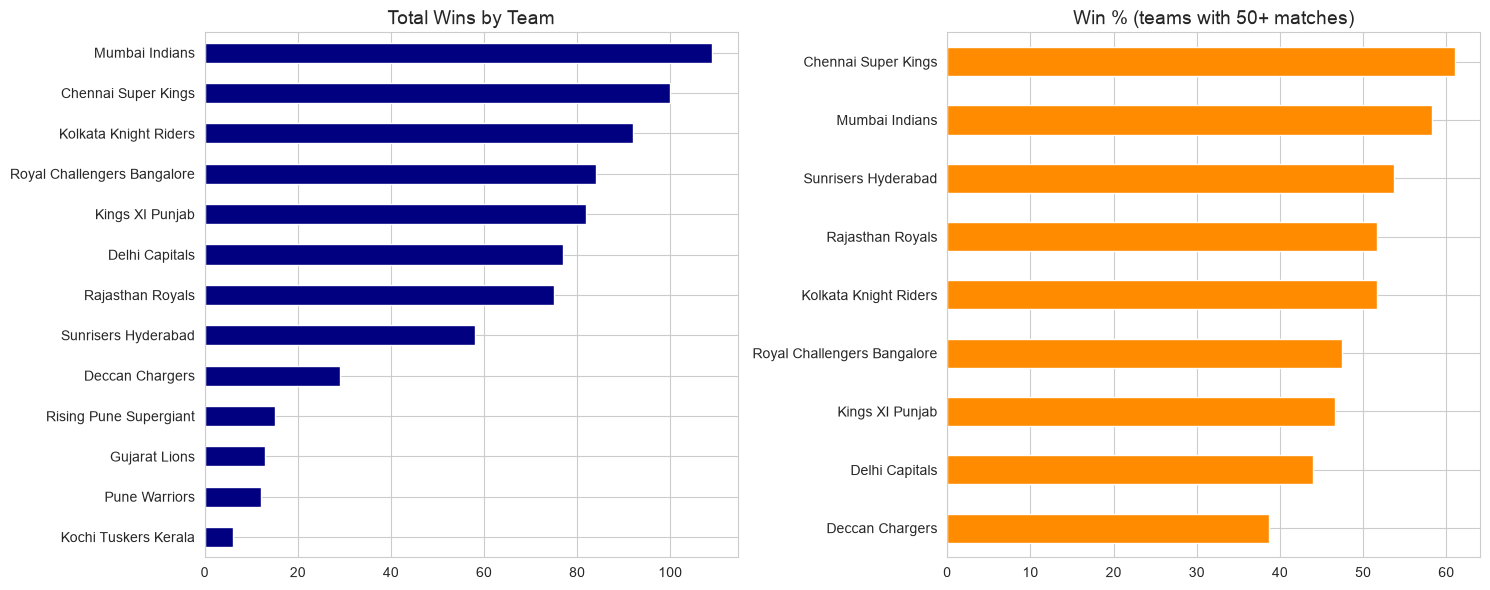

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
team_stats['wins'].sort_values().plot(kind='barh', ax=axes[0], color='navy')
axes[0].set_title('Total Wins by Team')
# win % only for teams with at least 50 matches
ts = team_stats[team_stats['matches'] >= 50]['win_pct'].sort_values()
ts.plot(kind='barh', ax=axes[1], color='darkorange')
axes[1].set_title('Win % (teams with 50+ matches)')
save('06_team_wins_and_winpct')

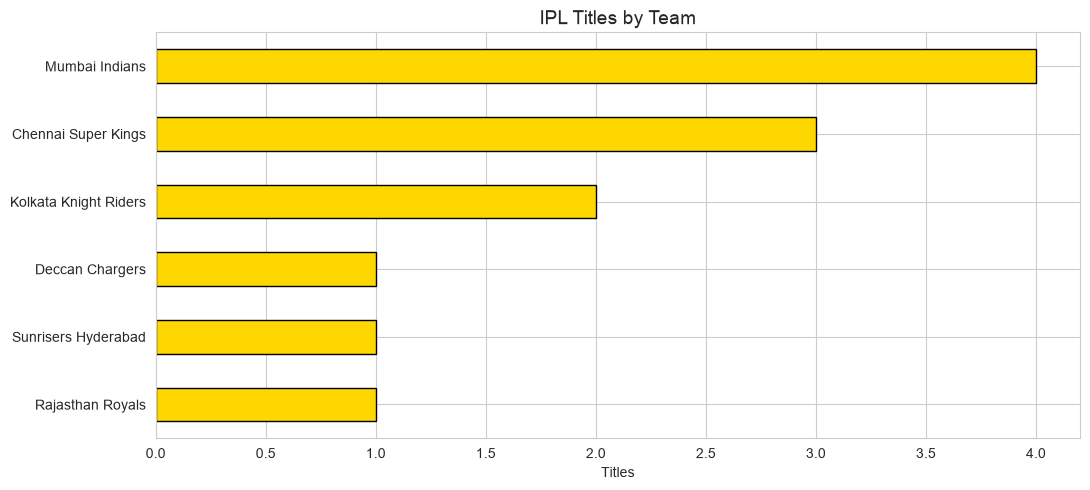

In [20]:
team_stats[team_stats['titles'] > 0]['titles'].sort_values().plot(kind='barh', color='gold', edgecolor='black')
plt.title('IPL Titles by Team'); plt.xlabel('Titles')
save('07_titles')

### 5.2 Wins by team across seasons (heatmap)

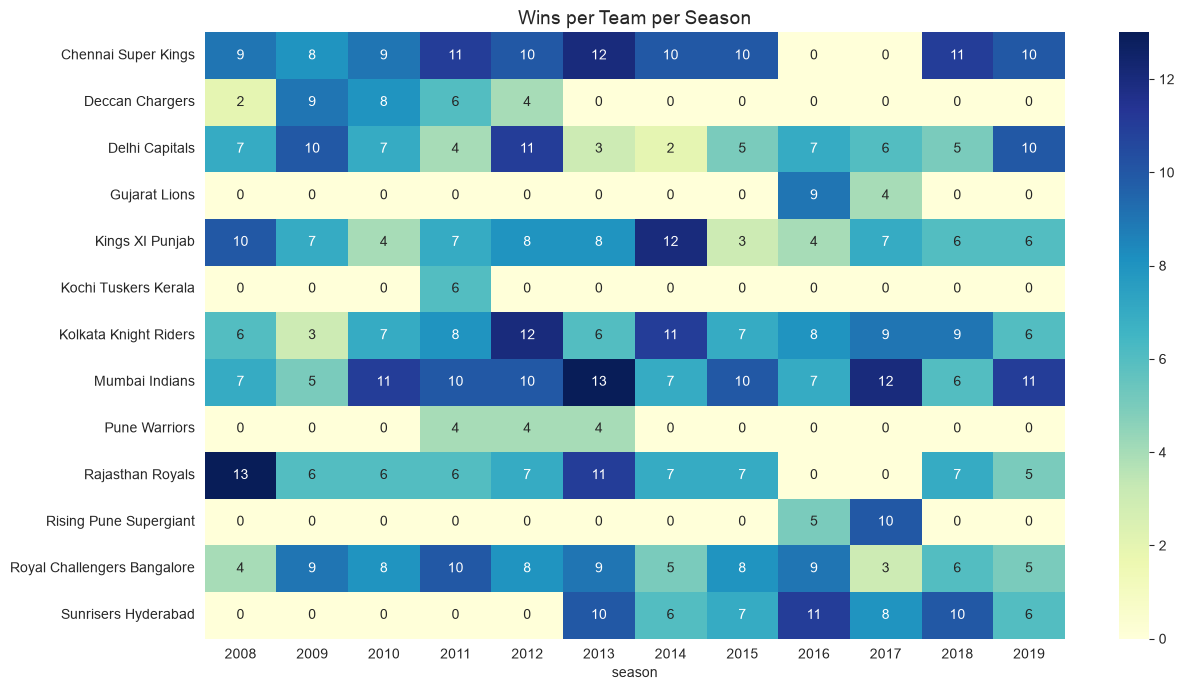

In [21]:
heat = played.pivot_table(index='winner', columns='season', values='id', aggfunc='count').fillna(0)
plt.figure(figsize=(13, 7))
sns.heatmap(heat, annot=True, fmt='.0f', cmap='YlGnBu')
plt.title('Wins per Team per Season'); plt.ylabel('')
save('08_team_season_heatmap')

## Step 6: Success Analysis - Top Performing Players
### 6.1 Batsmen

In [22]:
legal = deliveries[(deliveries['wide_runs'] == 0) & (deliveries['is_super_over'] == 0)]   # balls faced (wides are not faced)
reg = deliveries[deliveries['is_super_over'] == 0]

bat = reg.groupby('batsman').agg(runs=('batsman_runs', 'sum'),
                                 fours=('batsman_runs', lambda x: (x == 4).sum()),
                                 sixes=('batsman_runs', lambda x: (x == 6).sum()))
bat['balls'] = legal.groupby('batsman').size()
bat['innings'] = reg.groupby('batsman')['match_id'].nunique()
dismissals = reg[reg['player_dismissed'].notnull()].groupby('player_dismissed').size()
bat['dismissals'] = dismissals
bat['dismissals'] = bat['dismissals'].fillna(0)
bat['average'] = (bat['runs'] / bat['dismissals'].replace(0, np.nan)).round(2)
bat['strike_rate'] = (bat['runs'] / bat['balls'] * 100).round(2)
bat['seasons'] = reg.groupby('batsman')['season'].nunique()

top_runs = bat.sort_values('runs', ascending=False).head(10)
top_runs[['innings', 'runs', 'average', 'strike_rate', 'fours', 'sixes', 'seasons']]

,innings,runs,average,strike_rate,fours,sixes,seasons
batsman,,,,,,,
V Kohli,169,5429,37.97,132.03,481,191,12
SK Raina,189,5407,33.58,138.15,495,194,12
RG Sharma,182,4914,31.70,131.25,431,194,12
DA Warner,126,4741,43.50,143.45,459,181,10
S Dhawan,158,4632,33.81,126.18,526,96,12
CH Gayle,124,4535,41.99,152.69,373,326,11
MS Dhoni,170,4477,42.64,139.25,297,207,12
RV Uthappa,170,4446,29.06,131.38,436,156,12
AB de Villiers,142,4415,40.14,151.87,357,212,12


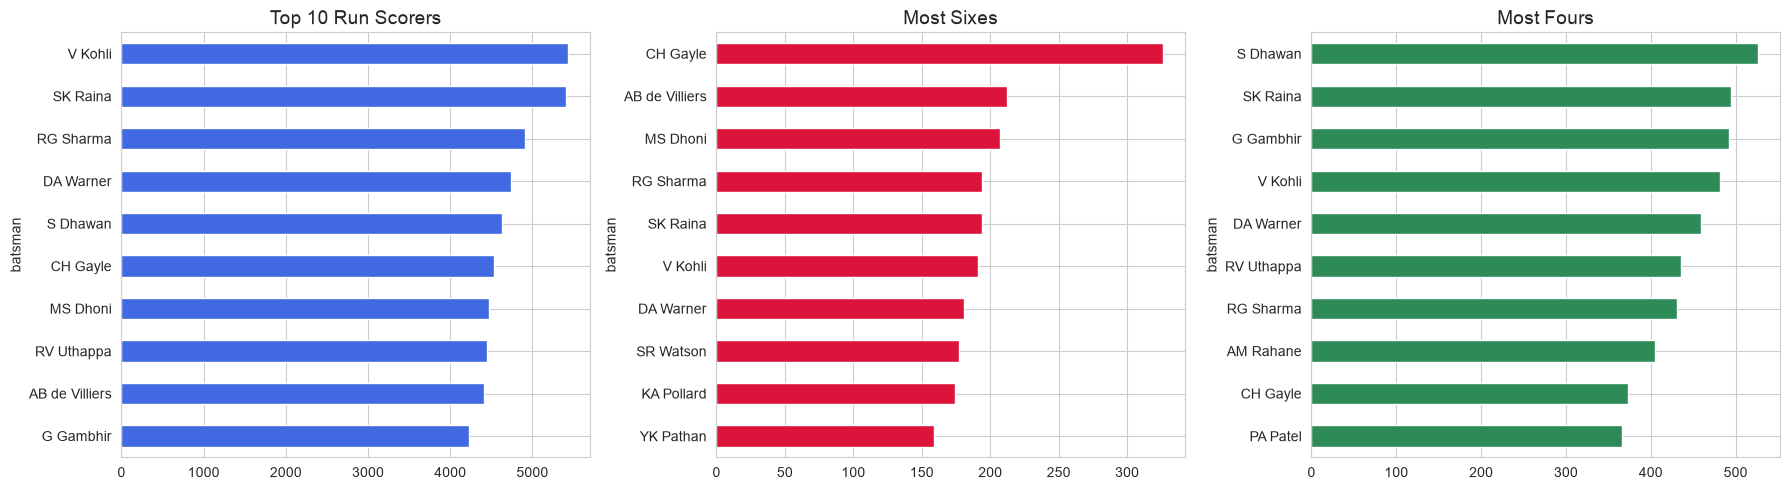

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
top_runs['runs'][::-1].plot(kind='barh', ax=axes[0], color='royalblue'); axes[0].set_title('Top 10 Run Scorers')
bat['sixes'].nlargest(10)[::-1].plot(kind='barh', ax=axes[1], color='crimson'); axes[1].set_title('Most Sixes')
bat['fours'].nlargest(10)[::-1].plot(kind='barh', ax=axes[2], color='seagreen'); axes[2].set_title('Most Fours')
save('09_top_batsmen')

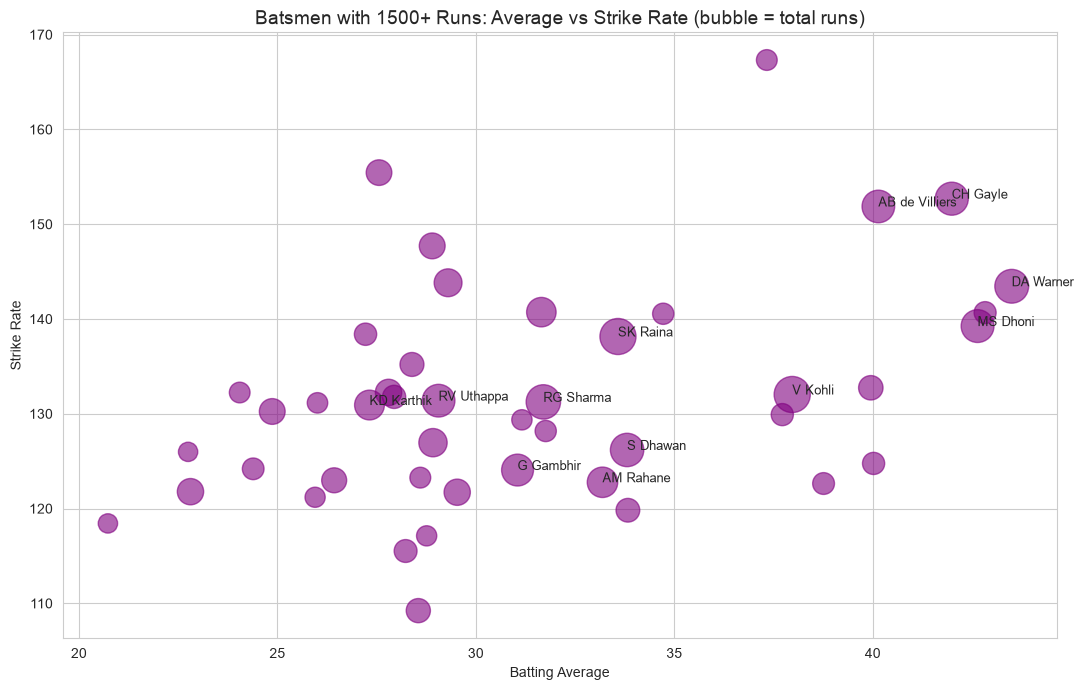

In [24]:
# Strike rate vs average for serious batsmen (min 1500 runs)
q = bat[bat['runs'] >= 1500]
plt.figure(figsize=(11, 7))
plt.scatter(q['average'], q['strike_rate'], s=q['runs'] / 8, alpha=0.6, color='purple')
for name, r in q.nlargest(12, 'runs').iterrows():
    plt.annotate(name, (r['average'], r['strike_rate']), fontsize=9)
plt.xlabel('Batting Average'); plt.ylabel('Strike Rate')
plt.title('Batsmen with 1500+ Runs: Average vs Strike Rate (bubble = total runs)')
save('10_avg_vs_strike_rate')

In [25]:
print('Best strike rate (min 1000 balls):')
print(bat[bat['balls'] >= 1000].nlargest(8, 'strike_rate')[['runs', 'balls', 'strike_rate']])

Best strike rate (min 1000 balls):
                runs  balls  strike_rate
batsman                                 
RR Pant         1792   1071       167.32
V Sehwag        2728   1755       155.44
CH Gayle        4535   2970       152.69
AB de Villiers  4415   2907       151.87
KA Pollard      2774   1878       147.71
YK Pathan       3223   2241       143.82
DA Warner       4741   3305       143.45
SR Watson       3608   2564       140.72


### 6.2 Bowlers

In [26]:
wicket_kinds = ['caught', 'bowled', 'lbw', 'stumped', 'caught and bowled', 'hit wicket']   # run outs are not credited to the bowler
bowl_legal = reg[(reg['wide_runs'] == 0) & (reg['noball_runs'] == 0)]

bowl = pd.DataFrame()
bowl['wickets'] = reg[reg['dismissal_kind'].isin(wicket_kinds)].groupby('bowler').size()
bowl['balls'] = bowl_legal.groupby('bowler').size()
# runs conceded by bowler = total runs minus byes, leg byes and penalty
reg = reg.assign(bowler_runs=reg['total_runs'] - reg['bye_runs'] - reg['legbye_runs'] - reg['penalty_runs'])
bowl['runs_conceded'] = reg.groupby('bowler')['bowler_runs'].sum()
bowl['wickets'] = bowl['wickets'].fillna(0)
bowl['overs'] = (bowl['balls'] / 6).round(1)
bowl['economy'] = (bowl['runs_conceded'] / (bowl['balls'] / 6)).round(2)
bowl['strike_rate'] = (bowl['balls'] / bowl['wickets'].replace(0, np.nan)).round(1)
bowl['seasons'] = reg.groupby('bowler')['season'].nunique()

top_wkts = bowl.sort_values('wickets', ascending=False).head(10)
top_wkts[['overs', 'wickets', 'economy', 'strike_rate', 'seasons']]

,overs,wickets,economy,strike_rate,seasons
bowler,,,,,
SL Malinga,471.2,170,7.19,16.6,9
A Mishra,517.0,156,7.36,19.9,12
Harbhajan Singh,562.3,150,7.08,22.5,12
PP Chawla,520.8,149,7.85,21.0,12
DJ Bravo,431.0,147,8.50,17.6,10
B Kumar,435.3,133,7.32,19.6,9
R Ashwin,487.5,125,6.85,23.4,10
SP Narine,426.2,122,6.74,21.0,8
UT Yadav,413.8,119,8.54,20.9,10


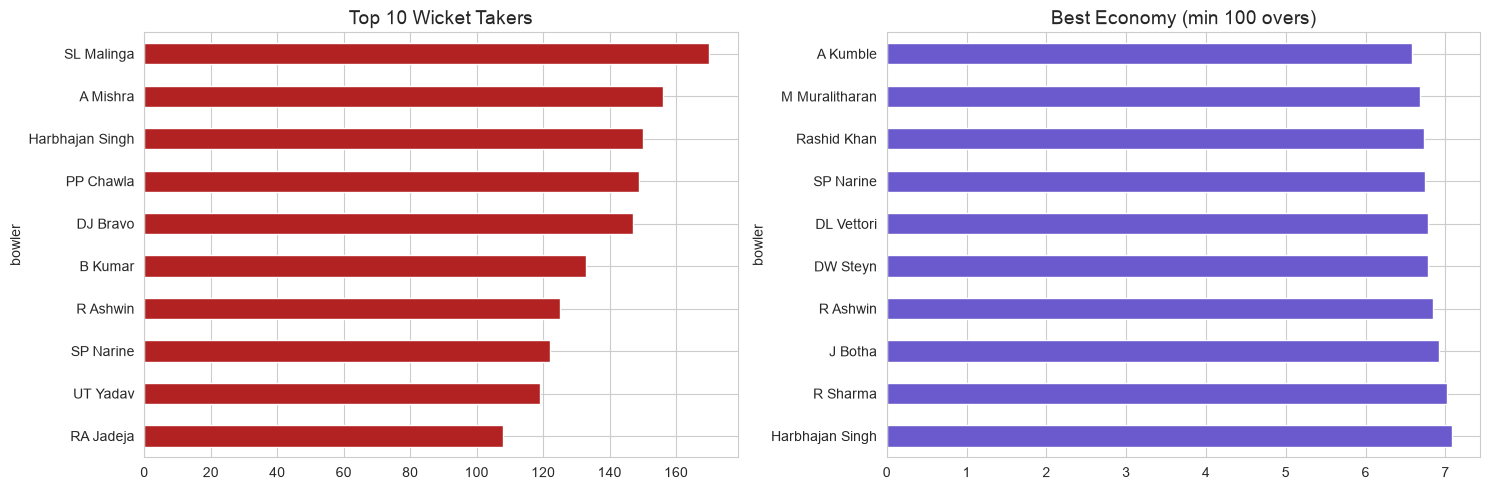

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
top_wkts['wickets'][::-1].plot(kind='barh', ax=axes[0], color='firebrick'); axes[0].set_title('Top 10 Wicket Takers')
eco = bowl[bowl['balls'] >= 600].nsmallest(10, 'economy')
eco['economy'][::-1].plot(kind='barh', ax=axes[1], color='slateblue'); axes[1].set_title('Best Economy (min 100 overs)')
save('11_top_bowlers')

### 6.3 Player of the Match awards

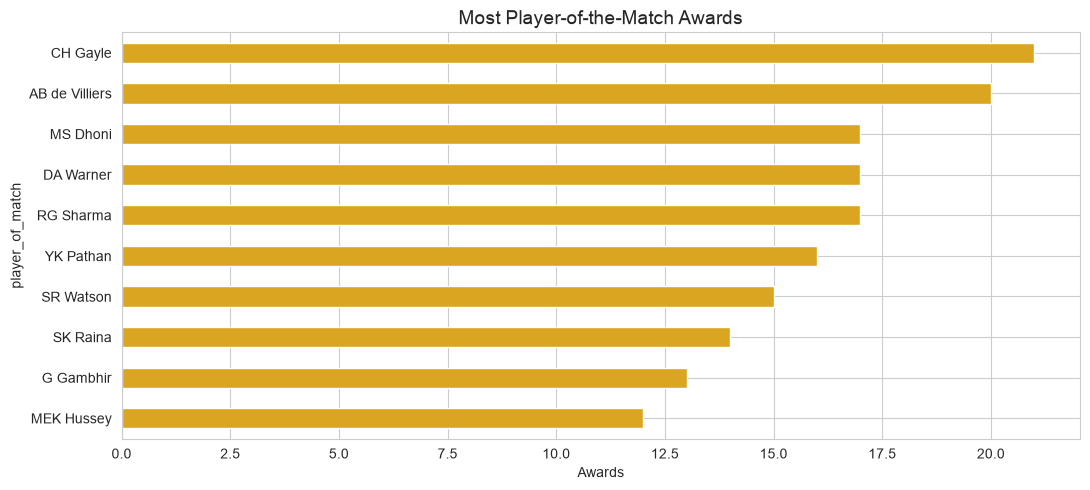

In [28]:
pom = matches[matches['player_of_match'] != 'No Award']['player_of_match'].value_counts().head(10)
pom[::-1].plot(kind='barh', color='goldenrod')
plt.title('Most Player-of-the-Match Awards'); plt.xlabel('Awards')
save('12_player_of_match')

### 6.4 Top scorer and top wicket-taker of every season

In [29]:
season_bat = reg.groupby(['season', 'batsman'])['batsman_runs'].sum().reset_index()
orange = season_bat.loc[season_bat.groupby('season')['batsman_runs'].idxmax()].rename(columns={'batsman': 'top_scorer', 'batsman_runs': 'runs'})
season_bowl = reg[reg['dismissal_kind'].isin(wicket_kinds)].groupby(['season', 'bowler']).size().reset_index(name='wickets')
purple = season_bowl.loc[season_bowl.groupby('season')['wickets'].idxmax()].rename(columns={'bowler': 'top_wicket_taker'})
orange.merge(purple, on='season')

,season,top_scorer,runs,top_wicket_taker,wickets
0,2008,SE Marsh,616,Sohail Tanvir,22
1,2009,ML Hayden,572,RP Singh,23
2,2010,SR Tendulkar,618,PP Ojha,21
3,2011,CH Gayle,608,SL Malinga,28
4,2012,CH Gayle,733,M Morkel,25
5,2013,MEK Hussey,733,DJ Bravo,32
6,2014,RV Uthappa,660,MM Sharma,23
7,2015,DA Warner,562,DJ Bravo,26
8,2016,V Kohli,973,B Kumar,23
9,2017,DA Warner,641,B Kumar,26


## Step 7: Factors that contribute to wins or losses
We compare **winning** and **losing** team-innings on: total score, powerplay (overs 1-6), middle (7-15) and death (16-20) runs, and wickets lost.

In [30]:
r = reg[reg['inning'].isin([1, 2])].copy()
r['phase'] = pd.cut(r['over'], bins=[0, 6, 15, 20], labels=['Powerplay', 'Middle', 'Death'])
r['wicket'] = r['dismissal_kind'].notnull().astype(int)

summary = r.groupby(['match_id', 'inning', 'batting_team']).agg(total=('total_runs', 'sum'), wickets=('wicket', 'sum')).reset_index()
phase = r.pivot_table(index=['match_id', 'inning', 'batting_team'], columns='phase', values='total_runs', aggfunc='sum').reset_index()
summary = summary.merge(phase, on=['match_id', 'inning', 'batting_team'])
summary = summary.merge(played[['id', 'winner']], left_on='match_id', right_on='id')
summary['won'] = summary['batting_team'] == summary['winner']

factors = summary.groupby('won')[['total', 'Powerplay', 'Middle', 'Death', 'wickets']].mean().round(1)
factors.index = ['Lost', 'Won']
factors

,total,Powerplay,Middle,Death,wickets
Lost,149.0,43.4,64.1,42.7,7.2
Won,162.9,48.9,71.9,46.5,4.5


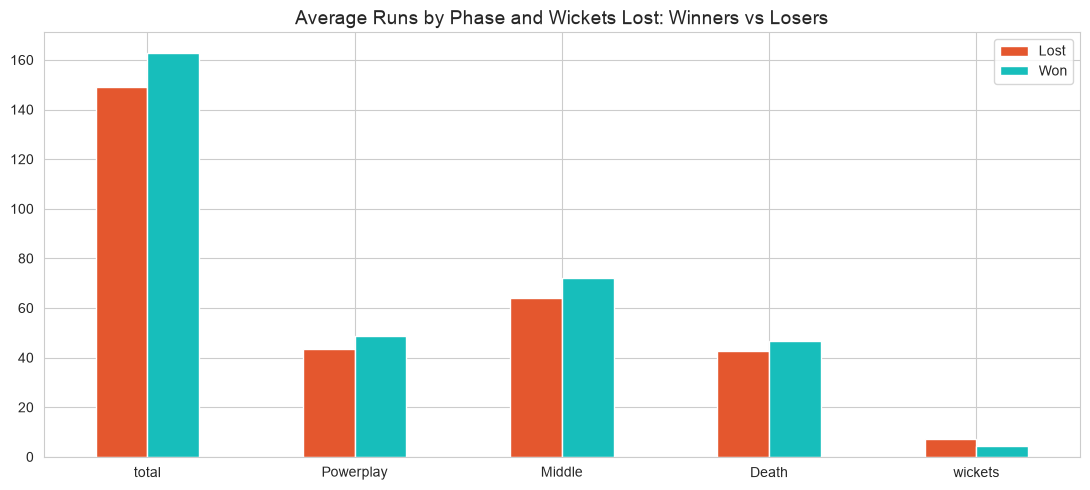

In [31]:
factors.T.plot(kind='bar', color=['#e4572e', '#17bebb'])
plt.title('Average Runs by Phase and Wickets Lost: Winners vs Losers'); plt.xticks(rotation=0)
save('13_win_loss_factors')

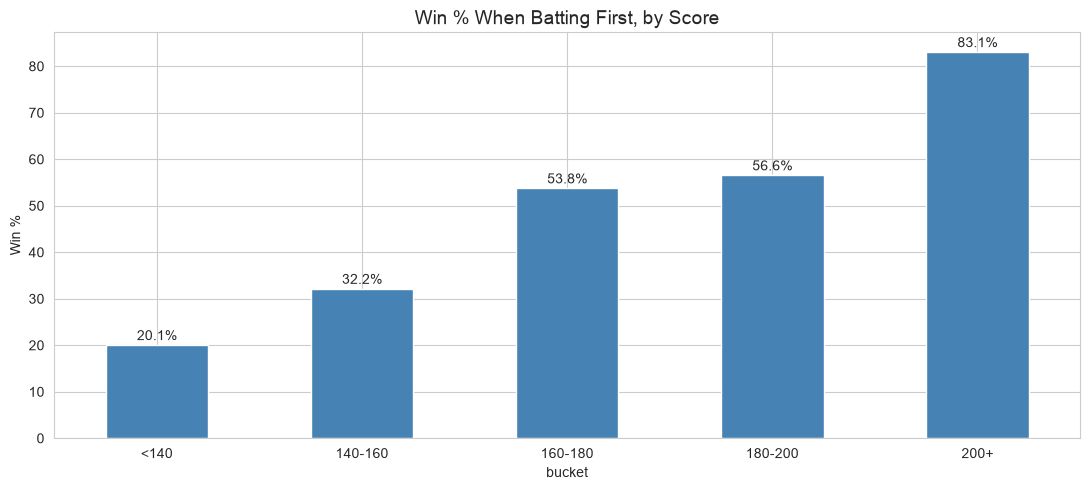

,win_pct_batting_first,matches
bucket,,
<140,20.1,169
140-160,32.2,174
160-180,53.8,195
180-200,56.6,143
200+,83.1,71


In [32]:
# How safe is a given first-innings total?
first = summary[summary['inning'] == 1].copy()
first['bucket'] = pd.cut(first['total'], bins=[0, 140, 160, 180, 200, 300], labels=['<140', '140-160', '160-180', '180-200', '200+'])
safe = first.groupby('bucket')['won'].agg(['mean', 'count'])
safe['mean'] = (safe['mean'] * 100).round(1)
safe.columns = ['win_pct_batting_first', 'matches']
ax = safe['win_pct_batting_first'].plot(kind='bar', color='steelblue')
for i, v in enumerate(safe['win_pct_batting_first']):
    ax.text(i, v + 1, f'{v}%', ha='center')
plt.title('Win % When Batting First, by Score'); plt.xticks(rotation=0); plt.ylabel('Win %')
save('14_first_innings_score_vs_win')
safe

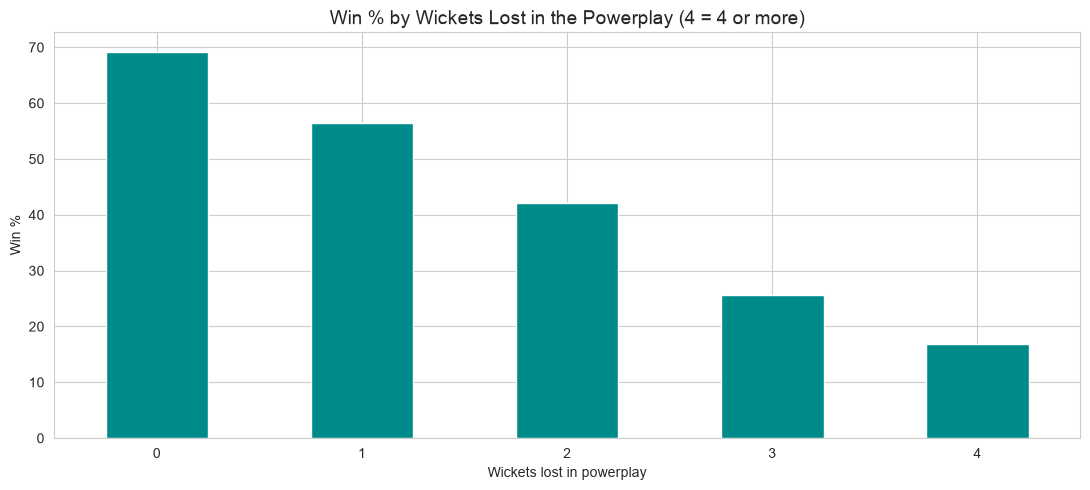

In [33]:
# Wickets lost in the powerplay vs result
pw = r[r['over'] <= 6].groupby(['match_id', 'batting_team'])['wicket'].sum().reset_index(name='pp_wkts')
pw = pw.merge(played[['id', 'winner']], left_on='match_id', right_on='id')
pw['won'] = pw['batting_team'] == pw['winner']
pw['pp_wkts'] = pw['pp_wkts'].clip(upper=4)
pw.groupby('pp_wkts')['won'].mean().mul(100).round(1).plot(kind='bar', color='darkcyan')
plt.title('Win % by Wickets Lost in the Powerplay (4 = 4 or more)'); plt.xlabel('Wickets lost in powerplay'); plt.ylabel('Win %'); plt.xticks(rotation=0)
save('15_powerplay_wickets_vs_win')

## Step 8: Endorsement Recommendations
The dataset has no social-media or brand data, so **popularity is approximated** by: Player-of-the-Match awards (fans notice match winners), total volume (runs / wickets), consistency across **seasons played** (longevity = brand recall), and for teams: **titles** and **win %**.

Performance + popularity score = average percentile rank of each metric (0 to 100).

In [34]:
# --- Batsmen ---
b = bat[bat['runs'] >= 1500].copy()
b['pom'] = matches['player_of_match'].value_counts().reindex(b.index).fillna(0)
for c in ['runs', 'strike_rate', 'average', 'sixes', 'pom', 'seasons']:
    b[c + '_pct'] = b[c].rank(pct=True) * 100
b['endorse_score'] = b[[c + '_pct' for c in ['runs', 'strike_rate', 'average', 'sixes', 'pom', 'seasons']]].mean(axis=1).round(1)
top_b = b.sort_values('endorse_score', ascending=False).head(8)
top_b[['runs', 'average', 'strike_rate', 'sixes', 'pom', 'seasons', 'endorse_score']]

,runs,average,strike_rate,sixes,pom,seasons,endorse_score
batsman,,,,,,,
AB de Villiers,4415,40.14,151.87,212,20,12,91.7
CH Gayle,4535,41.99,152.69,326,21,11,90.7
MS Dhoni,4477,42.64,139.25,207,17,12,89.4
DA Warner,4741,43.50,143.45,181,17,10,85.4
SK Raina,5407,33.58,138.15,194,14,12,84.1
V Kohli,5429,37.97,132.03,191,12,12,83.1
RG Sharma,4914,31.70,131.25,194,17,12,81.1
YK Pathan,3223,29.30,143.82,159,16,12,77.6


In [35]:
# --- Bowlers ---
w = bowl[bowl['wickets'] >= 80].copy()
w['pom'] = matches['player_of_match'].value_counts().reindex(w.index).fillna(0)
w['eco_inv'] = -w['economy']          # lower economy is better
w['sr_inv'] = -w['strike_rate']       # lower strike rate is better
for c in ['wickets', 'eco_inv', 'sr_inv', 'pom', 'seasons']:
    w[c + '_pct'] = w[c].rank(pct=True) * 100
w['endorse_score'] = w[[c + '_pct' for c in ['wickets', 'eco_inv', 'sr_inv', 'pom', 'seasons']]].mean(axis=1).round(1)
top_w = w.sort_values('endorse_score', ascending=False).head(8)
top_w[['wickets', 'economy', 'strike_rate', 'pom', 'seasons', 'endorse_score']]

,wickets,economy,strike_rate,pom,seasons,endorse_score
bowler,,,,,,
A Mishra,156,7.36,19.9,11.0,12,86.0
SL Malinga,170,7.19,16.6,6.0,9,79.6
Harbhajan Singh,150,7.08,22.5,8.0,12,75.6
B Kumar,133,7.32,19.6,5.0,9,67.6
SP Narine,122,6.74,21.0,9.0,8,67.2
PP Chawla,149,7.85,21.0,3.0,12,63.6
RA Jadeja,108,7.63,23.1,8.0,11,62.0
A Nehra,106,7.85,18.0,6.0,9,60.0


In [36]:
# --- Teams ---
t = team_stats[team_stats['matches'] >= 100].copy()
t['score'] = ((t['win_pct'].rank(pct=True) + t['titles'].rank(pct=True) + t['wins'].rank(pct=True)) / 3 * 100).round(1)
t = t.sort_values('score', ascending=False)
t[['matches', 'wins', 'win_pct', 'titles', 'score']]

,matches,wins,win_pct,titles,score
Mumbai Indians,187,109,58.3,4,95.8
Chennai Super Kings,164,100,61.0,3,91.7
Kolkata Knight Riders,178,92,51.7,2,68.8
Sunrisers Hyderabad,108,58,53.7,1,47.9
Rajasthan Royals,145,75,51.7,1,45.8
Royal Challengers Bangalore,177,84,47.5,0,41.7
Kings XI Punjab,176,82,46.6,0,33.3
Delhi Capitals,175,77,44.0,0,25.0


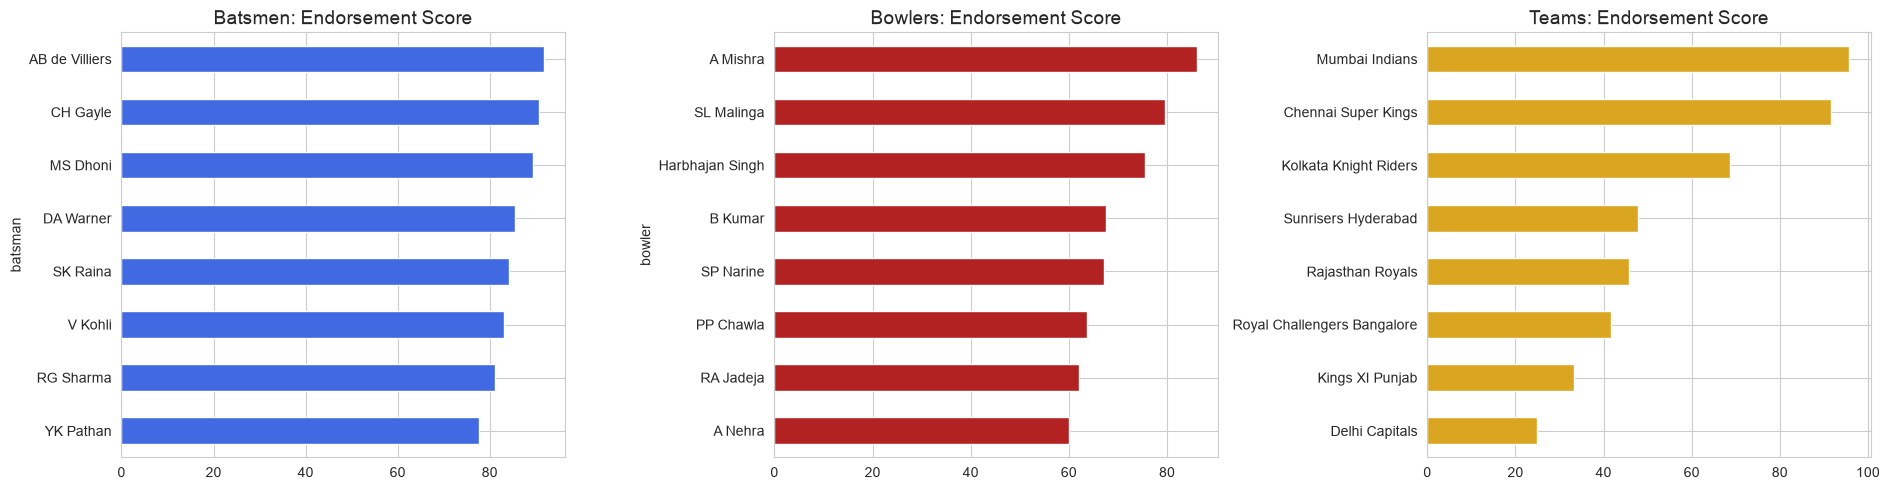

In [37]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
top_b['endorse_score'][::-1].plot(kind='barh', ax=axes[0], color='royalblue'); axes[0].set_title('Batsmen: Endorsement Score')
top_w['endorse_score'][::-1].plot(kind='barh', ax=axes[1], color='firebrick'); axes[1].set_title('Bowlers: Endorsement Score')
t['score'][::-1].plot(kind='barh', ax=axes[2], color='goldenrod'); axes[2].set_title('Teams: Endorsement Score')
save('16_endorsement_scores')

## Step 9: Key Insights
1. **Most successful teams:** Mumbai Indians lead in wins (109) and titles (4). Chennai Super Kings have the best win % (61.0%) with 3 titles. Kolkata Knight Riders have 2 titles. Delhi Capitals (44.0% wins) and Royal Challengers Bangalore (47.5%) have won no title in this data.
2. **Top players:** Virat Kohli (5,429) and Suresh Raina (5,407) are the top run scorers. Chris Gayle has the most sixes (326) and a 152.7 strike rate. Lasith Malinga leads wickets (170) and Amit Mishra, Harbhajan Singh are next.
3. **Toss:** The toss winner won only 52.3% of matches, so the toss is a weak factor.
4. **Batting first vs chasing:** Chasing teams won 55.2% of matches. Captains who chose to field after winning the toss won 56.3% of the time.
5. **What wins matches:** Winning teams scored about 163 vs 149 for losers, scored more in every phase (powerplay 48.9 vs 43.4, death overs 46.5 vs 42.7) and lost fewer wickets (4.5 vs 7.2).
6. **Safe totals:** Batting first, a total of 200+ wins 83.1% of matches, while below 140 wins only 20.1%.
7. **Scoring is rising:** average first-innings score went from about 150-165 (2008 to 2017) to about 180 in 2018.
8. **Endorsements:** Best batsmen are AB de Villiers, Chris Gayle and MS Dhoni. Best bowlers are Amit Mishra, Lasith Malinga and Harbhajan Singh. Best teams are Mumbai Indians and Chennai Super Kings.

## Step 10: Conclusion
IPL success is driven by strong powerplay and death-over batting, keeping wickets in hand, and bowling economy rather than by the toss. Mumbai Indians and Chennai Super Kings are the most successful franchises. Players such as AB de Villiers, Chris Gayle and MS Dhoni combine high performance with long careers and many Player-of-the-Match awards, which makes them the strongest candidates for product endorsements. Limitation: the data has no social-media or brand data, so popularity is estimated from awards and longevity, and the data ends at IPL 2019.

## Step 11: Advanced Storytelling (Storyboard plan)
Use the charts saved in the `images/` folder. Build the storyboard in **PowerPoint / Canva / Power BI** and record audio with the built-in recorder (PowerPoint: *Insert > Audio > Record Audio*, or *Slide Show > Record Slide Show*).

| Slide | Image from `images/` | Annotation to add (arrow + text box) | Audio script (about 20 seconds) |
|---|---|---|---|
| 1. Title | - | IPL EDA 2008-2019 | Introduce yourself, the task and the dataset. |
| 2. Dataset | - | 756 matches, about 179k deliveries | Explain matches and deliveries files and your cleaning. |
| 3. Growth | 01_matches_per_season | Circle the tallest bars | Explain how the league grew. |
| 4. Toss | 02, 03 | Highlight the toss win % | The toss matters less than people think. |
| 5. Top teams | 06, 07 | Circle the leader in wins and titles | Say which team is the most successful and why. |
| 6. Season story | 08 | Highlight the dominant seasons | Show how teams rise and fall. |
| 7. Batting stars | 09, 10 | Label the top 3 run scorers | Explain average vs strike rate. |
| 8. Bowling stars | 11 | Label the top 3 | Wickets vs economy. |
| 9. Win factors | 13, 14, 15 | Underline powerplay and death overs | What separates winners from losers. |
| 10. Endorsements | 16 | Highlight the top batsman, bowler and team | Your recommendations with reasons. |
| 11. Conclusion | - | 3 key takeaways | Summarize and thank the viewer. |

**Animations:** use the *Appear* or *Wipe* animation for each chart and annotation so insights show one at a time while you speak.